1. Membaca Dataset

In [1]:
import html
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

data_buku = pd.read_csv(
    "dataset/Books.csv",
    dtype={"ISBN": str, "Year-Of-Publication": str},
)

data_rating = pd.read_csv(
    "dataset/Ratings.csv",
    dtype={"ISBN": str},
)

data_user = pd.read_csv("dataset/Users.csv")

print(f"data_buku   : {data_buku.shape[0]:,} baris x {data_buku.shape[1]} kolom")
print(f"data_rating : {data_rating.shape[0]:,} baris x {data_rating.shape[1]} kolom")
print(f"data_user   : {data_user.shape[0]:,} baris x {data_user.shape[1]} kolom")

print("\n1. Data Buku")
display(data_buku.head(3))

print("\n2. Data Rating")
display(data_rating.head(3))

print("\n3. Data User")
display(data_user.head(3))

data_buku   : 271,360 baris x 8 kolom
data_rating : 1,149,780 baris x 3 kolom
data_user   : 278,858 baris x 3 kolom

1. Data Buku


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...



2. Data Rating


,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0



3. Data User


,User-ID,Location,Age
0,1,"nyc, new york, usa",NaN
1,2,"stockton, california, usa",18.0
2,3,"moscow, yukon territory, russia",NaN


2. Exploratory Data Analysis (EDA)

In [2]:
print("1. Cek Data Kosong")
print("\nData Buku:\n", data_buku.isna().sum())
print("\nData Rating:\n", data_rating.isna().sum())
print("\nData User:\n", data_user.isna().sum())

print("\n2. Cek Baris Duplikat")
print("Duplikat data buku  :", data_buku.duplicated().sum())
print("Duplikat data rating:", data_rating.duplicated().sum())
print("Duplikat data user  :", data_user.duplicated().sum())

print("\n3. Jumlah Data Unik")
print("Jumlah ISBN buku       :", data_buku["ISBN"].nunique())
print("Jumlah judul buku      :", data_buku["Book-Title"].nunique())
print("Jumlah user yg menilai :", data_rating["User-ID"].nunique())

print("\n4. Perbandingan Rating 0 (yang belum diberi rating oleh user) dan Rating 1-10 (Skor yang sudah di beri user)")
total_data = len(data_rating)
jumlah_tanpa_skor = (data_rating["Book-Rating"] == 0).sum()
jumlah_dengan_skor = (data_rating["Book-Rating"] > 0).sum()

persen_tanpa_skor = (jumlah_tanpa_skor / total_data) * 100
persen_dengan_skor = (jumlah_dengan_skor / total_data) * 100

print(f"Rating 0 (Tanpa Skor) : {jumlah_tanpa_skor:,} ({persen_tanpa_skor:.2f}%)")
print(f"Rating 1-10 (Skor asli dari user): {jumlah_dengan_skor:,} ({persen_dengan_skor:.2f}%)")

1. Cek Data Kosong

Data Buku:
 ISBN                   0
Book-Title             0
Book-Author            2
Year-Of-Publication    0
Publisher              2
Image-URL-S            0
Image-URL-M            0
Image-URL-L            3
dtype: int64

Data Rating:
 User-ID        0
ISBN           0
Book-Rating    0
dtype: int64

Data User:
 User-ID          0
Location         0
Age         110762
dtype: int64

2. Cek Baris Duplikat
Duplikat data buku  : 0
Duplikat data rating: 0
Duplikat data user  : 0

3. Jumlah Data Unik
Jumlah ISBN buku       : 271360
Jumlah judul buku      : 242135
Jumlah user yg menilai : 105283

4. Perbandingan Rating 0 (yang belum diberi rating oleh user) dan Rating 1-10 (Skor yang sudah di beri user)
Rating 0 (Tanpa Skor) : 716,109 (62.28%)
Rating 1-10 (Skor asli dari user): 433,671 (37.72%)


In [3]:
print("5. Cek Tahun Terbit Buku yang Aneh")
tahun_buku = pd.to_numeric(data_buku["Year-Of-Publication"], errors="coerce")
tahun_bergeser = tahun_buku.isna().sum()
tahun_tidak_wajar = ((tahun_buku < 1400) | (tahun_buku > 2026)).sum()

print("Tahun rusak atau tipe datanya menjadi teks :", tahun_bergeser)
print("Tahun tidak wajar yaitu yang nilainya 0 atau lebih dari 2026 :", tahun_tidak_wajar)

print("\n6. Cek Usia User yang Aneh")
usia_user = data_user["Age"].dropna()
usia_kosong = data_user["Age"].isna().sum()
usia_tidak_wajar = ((usia_user < 5) | (usia_user > 100)).sum()

print("Usia kosong atau tidak diisi :", usia_kosong)
print("Usia tidak wajar yaitu yang kurang dari 5 atau lebih dari 100 tahun :", usia_tidak_wajar)

print("\n7. Sebaran Jumlah Rating per User & per Buku")
rating_per_user = data_rating.groupby("User-ID")["Book-Rating"].count()
rating_per_buku = data_rating.groupby("ISBN")["Book-Rating"].count()

print(f"1 user rata-rata menilai {rating_per_user.mean():.1f} buku , nilai tengah: {rating_per_user.median():.0f} buku")
print(f"1 buku rata-rata dinilai {rating_per_buku.mean():.1f} kali , nilai tengah: {rating_per_buku.median():.0f} kali")

5. Cek Tahun Terbit Buku yang Aneh
Tahun rusak atau tipe datanya menjadi teks : 3
Tahun tidak wajar yaitu yang nilainya 0 atau lebih dari 2026 : 4631

6. Cek Usia User yang Aneh
Usia kosong atau tidak diisi : 110762
Usia tidak wajar yaitu yang kurang dari 5 atau lebih dari 100 tahun : 1248

7. Sebaran Jumlah Rating per User & per Buku
1 user rata-rata menilai 10.9 buku , nilai tengah: 1 buku
1 buku rata-rata dinilai 3.4 kali , nilai tengah: 1 kali


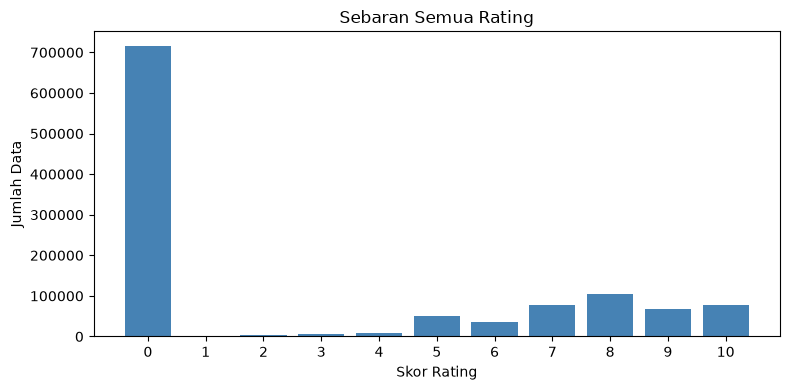

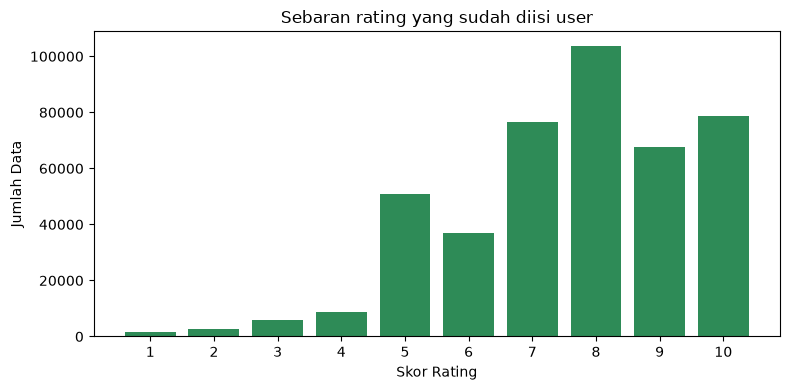

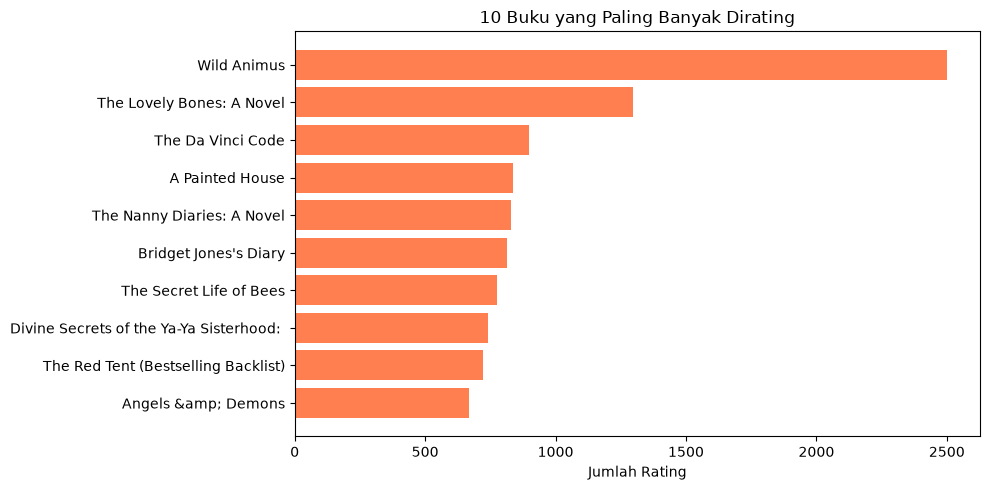

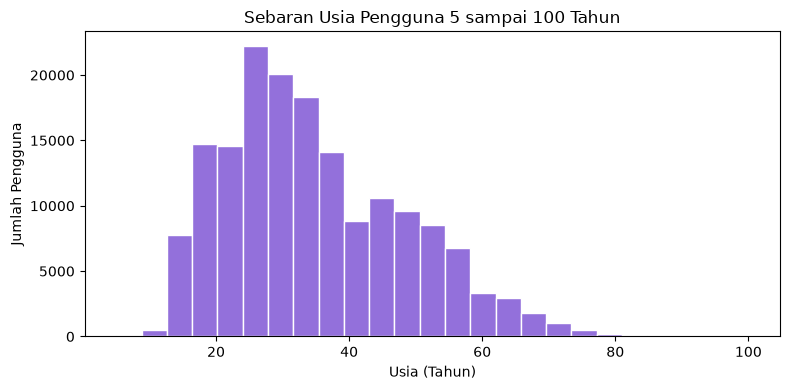

In [4]:
hitung_semua_rating = data_rating["Book-Rating"].value_counts().sort_index()

plt.figure(figsize=(8, 4))
plt.bar(hitung_semua_rating.index, hitung_semua_rating.values, color="steelblue")
plt.title("Sebaran Semua Rating")
plt.xlabel("Skor Rating")
plt.ylabel("Jumlah Data")
plt.xticks(range(0, 11))
plt.tight_layout()
plt.show()

rating_asli = data_rating[data_rating["Book-Rating"] > 0]
hitung_rating_asli = rating_asli["Book-Rating"].value_counts().sort_index()

plt.figure(figsize=(8, 4))
plt.bar(hitung_rating_asli.index, hitung_rating_asli.values, color="seagreen")
plt.title("Sebaran rating yang sudah diisi user")
plt.xlabel("Skor Rating")
plt.xticks(range(1, 11))
plt.tight_layout()
plt.show()

gabung_judul = data_rating.merge(data_buku[["ISBN", "Book-Title"]], on="ISBN", how="inner")
top_10_buku = gabung_judul["Book-Title"].value_counts().head(10).sort_values(ascending=True)
judul_pendek = top_10_buku.index.astype(str).str.slice(0, 40)

plt.figure(figsize=(10, 5))
plt.barh(judul_pendek, top_10_buku.values, color="coral")
plt.title("10 Buku yang Paling Banyak Dirating")
plt.xlabel("Jumlah Rating")
plt.tight_layout()
plt.show()

usia_wajar = data_user["Age"].dropna()
usia_wajar = usia_wajar[(usia_wajar >= 5) & (usia_wajar <= 100)]

plt.figure(figsize=(8, 4))
plt.hist(usia_wajar, bins=25, color="mediumpurple", edgecolor="white")
plt.title("Sebaran Usia Pengguna 5 sampai 100 Tahun")
plt.xlabel("Usia (Tahun)")
plt.ylabel("Jumlah Pengguna")
plt.tight_layout()
plt.show()

3. Data Cleaning & Filtering

In [5]:
buku_bersih = data_buku.copy()

def rapikan_baris_buku(df, isbn, judul, penulis, tahun, penerbit):
    baris = df["ISBN"] == isbn
    df.loc[baris, "Book-Title"] = judul
    df.loc[baris, "Book-Author"] = penulis
    df.loc[baris, "Year-Of-Publication"] = tahun
    df.loc[baris, "Publisher"] = penerbit
    df.loc[baris, "Image-URL-S"] = f"http://images.amazon.com/images/P/{isbn}.01.THUMBZZZ.jpg"
    df.loc[baris, "Image-URL-M"] = f"http://images.amazon.com/images/P/{isbn}.01.MZZZZZZZ.jpg"
    df.loc[baris, "Image-URL-L"] = f"http://images.amazon.com/images/P/{isbn}.01.LZZZZZZZ.jpg"

rapikan_baris_buku(
    buku_bersih, "078946697X",
    "DK Readers: Creating the X-Men, How It All Began (Level 4: Proficient Readers)",
    "Michael Teitelbaum", "2000", "DK Publishing Inc"
)
rapikan_baris_buku(
    buku_bersih, "0789466953",
    "DK Readers: Creating the X-Men, How Comic Books Come to Life (Level 4: Proficient Readers)",
    "James Buckley", "2000", "DK Publishing Inc"
)
rapikan_baris_buku(
    buku_bersih, "2070426769",
    "Peuple du ciel, suivi de Les Bergers",
    "Jean-Marie Gustave Le Clézio", "2003", "Gallimard"
)

for kolom in ["Book-Title", "Book-Author", "Publisher"]:
    buku_bersih[kolom] = buku_bersih[kolom].fillna("Unknown")
    buku_bersih[kolom] = buku_bersih[kolom].astype(str).map(html.unescape)
    buku_bersih[kolom] = buku_bersih[kolom].str.strip()

buku_bersih["Year-Of-Publication"] = pd.to_numeric(buku_bersih["Year-Of-Publication"], errors="coerce")
tahun_aneh = (buku_bersih["Year-Of-Publication"] < 1400) | (buku_bersih["Year-Of-Publication"] > 2026)
buku_bersih.loc[tahun_aneh, "Year-Of-Publication"] = np.nan

median_tahun = buku_bersih["Year-Of-Publication"].median()
buku_bersih["Year-Of-Publication"] = buku_bersih["Year-Of-Publication"].fillna(median_tahun).astype(int)

buku_bersih = buku_bersih.drop_duplicates(subset=["ISBN"]).copy()
buku_unik = buku_bersih.drop_duplicates(subset=["Book-Title"]).copy()

print("Cek data kosong di buku_bersih setelah dirapikan:")
print(buku_bersih.isna().sum())
print(f"\nJumlah buku bersih berdasarkan ISBN : {len(buku_bersih):,}")
print(f"Jumlah judul unik : {len(buku_unik):,}")

Cek data kosong di buku_bersih setelah dirapikan:
ISBN                   0
Book-Title             0
Book-Author            0
Year-Of-Publication    0
Publisher              0
Image-URL-S            0
Image-URL-M            0
Image-URL-L            0
dtype: int64

Jumlah buku bersih berdasarkan ISBN : 271,360
Jumlah judul unik : 242,131


In [6]:
rating_eksplisit = data_rating[
    (data_rating["Book-Rating"] >= 1) & (data_rating["Book-Rating"] <= 10)
].drop_duplicates().copy()

rating_dengan_buku = rating_eksplisit.merge(
    buku_bersih[["ISBN", "Book-Title", "Book-Author", "Year-Of-Publication", "Publisher", "Image-URL-L"]],
    on="ISBN",
    how="inner",
)

print(f"Total rating asli user : {len(rating_eksplisit):,}")
print(f"Total rating yang cocok dgn data buku : {len(rating_dengan_buku):,}")

print("\nhasil penggabungan rating dan data buku:")
display(rating_dengan_buku.head(3))

Total rating asli user : 433,671
Total rating yang cocok dgn data buku : 383,842

hasil penggabungan rating dan data buku:


,User-ID,ISBN,Book-Rating,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-L
0,276726,0155061224,5,Rites of Passage,Judith Rae,2001,Heinle,http://images.amazon.com/images/P/0155061224.0...
1,276729,052165615X,3,Help!: Level 1,Philip Prowse,1999,Cambridge University Press,http://images.amazon.com/images/P/052165615X.0...
2,276729,0521795028,6,The Amsterdam Connection : Level 4 (Cambridge ...,Sue Leather,2001,Cambridge University Press,http://images.amazon.com/images/P/0521795028.0...


In [7]:
data_siap_latih = (
    rating_dengan_buku.groupby(["Book-Title", "User-ID"], as_index=False)["Book-Rating"]
    .mean()
)

while True:
    jumlah_awal = len(data_siap_latih)

    hitung_buku = data_siap_latih.groupby("Book-Title")["User-ID"].count()
    buku_lolos = hitung_buku[hitung_buku >= 15].index
    data_siap_latih = data_siap_latih[data_siap_latih["Book-Title"].isin(buku_lolos)]

    hitung_user = data_siap_latih.groupby("User-ID")["Book-Title"].count()
    user_lolos = hitung_user[hitung_user >= 10].index
    data_siap_latih = data_siap_latih[data_siap_latih["User-ID"].isin(user_lolos)]

    if len(data_siap_latih) == jumlah_awal:
        break

data_siap_latih = data_siap_latih.copy()

tabel_pivot = data_siap_latih.pivot_table(
    index="Book-Title",
    columns="User-ID",
    values="Book-Rating",
)

jumlah_buku_model = tabel_pivot.shape[0]
jumlah_user_model = tabel_pivot.shape[1]
jumlah_rating_terisi = int(tabel_pivot.notna().sum().sum())
kepadatan = (jumlah_rating_terisi / (jumlah_buku_model * jumlah_user_model)) * 100

print("Ringkasan data akhir")
print(f"Jumlah Judul Buku   : {jumlah_buku_model:,}")
print(f"Jumlah User Aktif   : {jumlah_user_model:,}")
print(f"Total Rating Terisi : {jumlah_rating_terisi:,}")
print(f"Kepadatan Matriks   : {kepadatan:.2f}%")
print(f"Rating paling sedikit per user di matriks : {int(tabel_pivot.notna().sum(axis=0).min())}")
print(f"Rating paling sedikit per buku di matriks : {int(tabel_pivot.notna().sum(axis=1).min())}")

print("\nContoh tabel rating akhir:")
display(tabel_pivot.iloc[:5, :5])

Ringkasan data akhir
Jumlah Judul Buku   : 1,092
Jumlah User Aktif   : 1,530
Total Rating Terisi : 33,381
Kepadatan Matriks   : 2.00%
Rating paling sedikit per user di matriks : 10
Rating paling sedikit per buku di matriks : 15

Contoh tabel rating akhir:


User-ID,243,254,638,805,882
Book-Title,,,,,
1984,NaN,9.0,NaN,NaN,NaN
1st to Die: A Novel,NaN,NaN,NaN,NaN,NaN
2nd Chance,NaN,NaN,9.0,NaN,NaN
4 Blondes,NaN,NaN,NaN,NaN,NaN
84 Charing Cross Road,NaN,NaN,NaN,NaN,NaN


4. Pemodelan Sistem Rekomendasi

A. POPULARITY-BASED FILTERING

Tujuan: Menyusun daftar 50 buku terbaik untuk halaman Beranda aplikasi GUI

Syarat: Minimal dinilai 100 orang supaya rata-rata ratingnya bisa dipercaya

In [8]:
statistik_buku = (
    rating_dengan_buku.groupby("Book-Title", as_index=False)
    .agg(
        jumlah_rating=("Book-Rating", "count"),
        rata_rating=("Book-Rating", "mean"),
    )
)

buku_populer = statistik_buku[statistik_buku["jumlah_rating"] >= 100].copy()
buku_populer = buku_populer.sort_values(
    by=["rata_rating", "jumlah_rating"],
    ascending=[False, False],
).head(50)

buku_populer = buku_populer.merge(
    buku_unik[["Book-Title", "Book-Author", "Year-Of-Publication", "Publisher", "Image-URL-L"]],
    on="Book-Title",
    how="left",
)
buku_populer["rata_rating"] = buku_populer["rata_rating"].round(2)

print(f"Jumlah buku yang sudah dirating lebih dari 100: {(statistik_buku['jumlah_rating'] >= 100).sum()} buku")
print("\nTop 10 Buku Paling Populer:")
display(buku_populer[["Book-Title", "Book-Author", "jumlah_rating", "rata_rating"]].head(10))

Jumlah buku yang sudah dirating lebih dari 100: 200 buku

Top 10 Buku Paling Populer:


,Book-Title,Book-Author,jumlah_rating,rata_rating
0,"The Two Towers (The Lord of the Rings, Part 2)",J.R.R. TOLKIEN,136,9.33
1,"The Return of the King (The Lord of the Rings,...",J.R.R. TOLKIEN,103,9.21
2,Harry Potter and the Goblet of Fire (Book 4),J. K. Rowling,247,9.13
3,Harry Potter and the Sorcerer's Stone (Book 1),J. K. Rowling,176,9.06
4,Harry Potter and the Order of the Phoenix (Boo...,J. K. Rowling,211,9.05
5,Harry Potter and the Prisoner of Azkaban (Book 3),J. K. Rowling,277,9.04
6,To Kill a Mockingbird,Harper Lee,267,8.98
7,Harry Potter and the Sorcerer's Stone (Harry P...,J. K. Rowling,315,8.94
8,Ender's Game (Ender Wiggins Saga (Paperback)),Orson Scott Card,151,8.92
9,The Fellowship of the Ring (The Lord of the Ri...,J.R.R. TOLKIEN,205,8.88


B. ITEM-BASED COLLABORATIVE FILTERING

In [9]:
from sklearn.metrics.pairwise import cosine_similarity

matriks_item = tabel_pivot.fillna(0)

kemiripan_item = cosine_similarity(matriks_item)

df_kemiripan_item = pd.DataFrame(
    kemiripan_item,
    index=tabel_pivot.index,
    columns=tabel_pivot.index,
)

def rekomendasi_item_based(judul_buku, jumlah=5):
    if judul_buku not in df_kemiripan_item.index:
        return f"Buku '{judul_buku}' tidak ditemukan di model."

    skor_mirip = (
        df_kemiripan_item[judul_buku]
        .sort_values(ascending=False)
        .iloc[1 : jumlah + 1]
    )

    hasil = pd.DataFrame({
        "Book-Title": skor_mirip.index,
        "Skor Kemiripan": skor_mirip.values.round(3),
    }).merge(
        buku_unik[["Book-Title", "Book-Author", "Year-Of-Publication", "Image-URL-L"]],
        on="Book-Title",
        how="left",
    )
    return hasil

contoh_buku = "Harry Potter and the Prisoner of Azkaban (Book 3)"
if contoh_buku not in df_kemiripan_item.index:
    contoh_buku = df_kemiripan_item.index[0]

print(f"Jika user menyukai: '{contoh_buku}'")
print("Rekomendasi 5 buku paling mirip (Item-Based CF):")
display(rekomendasi_item_based(contoh_buku, jumlah=5)[["Book-Title", "Book-Author", "Skor Kemiripan"]])

Jika user menyukai: 'Harry Potter and the Prisoner of Azkaban (Book 3)'
Rekomendasi 5 buku paling mirip (Item-Based CF):


,Book-Title,Book-Author,Skor Kemiripan
0,Harry Potter and the Goblet of Fire (Book 4),J. K. Rowling,0.703
1,Harry Potter and the Chamber of Secrets (Book 2),J. K. Rowling,0.681
2,Harry Potter and the Sorcerer's Stone (Book 1),J. K. Rowling,0.511
3,Harry Potter and the Order of the Phoenix (Boo...,J. K. Rowling,0.491
4,Harry Potter and the Sorcerer's Stone (Harry P...,J. K. Rowling,0.346


C. USER-BASED COLLABORATIVE FILTERING

In [10]:
user_buku = tabel_pivot.T
matriks_user = user_buku.fillna(0)

kemiripan_user = cosine_similarity(matriks_user)
df_kemiripan_user = pd.DataFrame(
    kemiripan_user,
    index=user_buku.index,
    columns=user_buku.index,
)

def riwayat_user(user_id, jumlah=5):
    if user_id not in user_buku.index:
        return pd.DataFrame()
    rating_saya = user_buku.loc[user_id].dropna().sort_values(ascending=False).head(jumlah)
    hasil = pd.DataFrame({
        "Book-Title": rating_saya.index,
        "Rating Asli": rating_saya.values.round(1),
    }).merge(
        buku_unik[["Book-Title", "Book-Author", "Year-Of-Publication", "Image-URL-L"]],
        on="Book-Title",
        how="left",
    )
    return hasil

def rekomendasi_user_based(user_id, jumlah=5, top_n_neighbor=30, min_penilai=4):
    if user_id not in user_buku.index:
        return f"User ID {user_id} tidak ditemukan di model."

    skor_tetangga = df_kemiripan_user[user_id].drop(index=user_id)
    tetangga_mirip = skor_tetangga[skor_tetangga > 0].sort_values(ascending=False).head(top_n_neighbor)

    if tetangga_mirip.empty:
        return "Tidak ditemukan user lain dengan selera yang mirip."

    belum_dirating = user_buku.loc[user_id].isna()
    daftar_buku_belum = user_buku.columns[belum_dirating]

    rating_tetangga = user_buku.loc[tetangga_mirip.index, daftar_buku_belum]

    pembilang = rating_tetangga.fillna(0).mul(tetangga_mirip, axis=0).sum(axis=0)
    sudah_menilai = rating_tetangga.notna().astype(float)
    penyebut = sudah_menilai.mul(tetangga_mirip.abs(), axis=0).sum(axis=0)
    jumlah_penilai = sudah_menilai.sum(axis=0).astype(int)

    buku_valid = penyebut[jumlah_penilai >= min_penilai].index
    if len(buku_valid) < jumlah:
        buku_valid = penyebut[jumlah_penilai >= 2].index
    if len(buku_valid) < jumlah:
        buku_valid = penyebut[penyebut > 0].index

    if len(buku_valid) == 0:
        return "Belum ada buku yang cukup untuk direkomendasikan."

    prediksi_skor = pembilang[buku_valid] / penyebut[buku_valid]

    hasil = pd.DataFrame({
        "Book-Title": buku_valid,
        "Prediksi Rating": prediksi_skor.loc[buku_valid].round(2).values,
        "Tetangga Penilai": jumlah_penilai.loc[buku_valid].values,
    })
    hasil = hasil.sort_values(
        by=["Prediksi Rating", "Tetangga Penilai"],
        ascending=[False, False],
    ).head(jumlah).reset_index(drop=True)

    hasil = hasil.merge(
        buku_unik[["Book-Title", "Book-Author", "Year-Of-Publication", "Image-URL-L"]],
        on="Book-Title",
        how="left",
    )
    return hasil

contoh_user = user_buku.index[1]
print(f"Uji menggunakan user id: {contoh_user}")

print("\n5 Buku yang pernah disukai user ini:")
display(riwayat_user(contoh_user, jumlah=5)[["Book-Title", "Book-Author", "Rating Asli"]])

print("\nRekomendasi 5 buku baru untuk user ini menggunakan user based:")
display(rekomendasi_user_based(contoh_user, jumlah=5)[["Book-Title", "Book-Author", "Prediksi Rating", "Tetangga Penilai"]])

Uji menggunakan user id: 254

5 Buku yang pernah disukai user ini:


,Book-Title,Book-Author,Rating Asli
0,American Gods,Neil Gaiman,10.0
1,Neverwhere,Neil Gaiman,10.0
2,1984,George Orwell,9.0
3,Harry Potter and the Chamber of Secrets (Book 2),J. K. Rowling,9.0
4,Harry Potter and the Prisoner of Azkaban (Book 3),J. K. Rowling,9.0



Rekomendasi 5 buku baru untuk user ini menggunakan user based:


,Book-Title,Book-Author,Prediksi Rating,Tetangga Penilai
0,The Hobbit : The Enchanting Prelude to The Lor...,J.R.R. TOLKIEN,10.00,4
1,"The Two Towers (The Lord of the Rings, Part 2)",J.R.R. TOLKIEN,9.65,11
2,"The Return of the King (The Lord of the Rings,...",J.R.R. TOLKIEN,9.63,8
3,Harry Potter and the Order of the Phoenix (Boo...,J. K. Rowling,9.37,18
4,To Kill a Mockingbird,Harper Lee,9.33,4


In [11]:
judul_dicek = "The Two Towers (The Lord of the Rings, Part 2)"

skor_semua = df_kemiripan_user[contoh_user].drop(index=contoh_user)
tetangga_30 = skor_semua[skor_semua > 0].sort_values(ascending=False).head(30)

rating_penilai = user_buku.loc[tetangga_30.index, judul_dicek].dropna()
sim_penilai = tetangga_30.loc[rating_penilai.index]

tabel_rincian = pd.DataFrame({
    "User-ID Tetangga": rating_penilai.index,
    "Similarity (w)": sim_penilai.values.round(4),
    "Rating Buku (r)": rating_penilai.values,
    "w * r": (sim_penilai.values * rating_penilai.values).round(4),
})

display(tabel_rincian)
total_pembilang = (sim_penilai.values * rating_penilai.values).sum()
total_penyebut = sim_penilai.abs().values.sum()
print(f"Total Pembilang sum(w * r) = {total_pembilang:.4f}")
print(f"Total Penyebut  sum(|w|)   = {total_penyebut:.4f}")
print(f"Prediksi Rating            = {total_pembilang:.4f} / {total_penyebut:.4f} = {total_pembilang / total_penyebut:.2f}")

,User-ID Tetangga,Similarity (w),Rating Buku (r),w * r
0,124876,0.4005,10.0,4.0053
1,105221,0.3799,10.0,3.7993
2,52350,0.3582,9.0,3.2238
3,226965,0.3075,10.0,3.0747
4,116904,0.3069,10.0,3.0687
5,102702,0.2776,10.0,2.7759
6,215986,0.2768,10.0,2.7681
7,115572,0.2749,8.0,2.1993
8,193469,0.2745,10.0,2.7445
9,137742,0.2634,10.0,2.6338


Total Pembilang sum(w * r) = 32.6369
Total Penyebut  sum(|w|)   = 3.3805
Prediksi Rating            = 32.6369 / 3.3805 = 9.65


5. Evaluasi Perbandingan Model

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

data_latih, data_uji = train_test_split(data_siap_latih, test_size=0.2, random_state=42)

pivot_latih = data_latih.pivot_table(index="Book-Title", columns="User-ID", values="Book-Rating")
user_latih = pivot_latih.T

df_sim_item_latih = pd.DataFrame(
    cosine_similarity(pivot_latih.fillna(0)),
    index=pivot_latih.index,
    columns=pivot_latih.index,
)
df_sim_user_latih = pd.DataFrame(
    cosine_similarity(user_latih.fillna(0)),
    index=user_latih.index,
    columns=user_latih.index,
)

def prediksi_rating_user_based(user_id, judul_buku, k=30):
    if (judul_buku not in pivot_latih.index) or (user_id not in pivot_latih.columns):
        return np.nan
    penilai = pivot_latih.loc[judul_buku].dropna()
    sim = df_sim_user_latih.loc[user_id, penilai.index]
    top_k = sim[sim > 0].sort_values(ascending=False).head(k)
    if top_k.empty:
        return np.nan
    return float((top_k * penilai.loc[top_k.index]).sum() / top_k.abs().sum())

def prediksi_rating_item_based(user_id, judul_buku, k=30):
    if (judul_buku not in pivot_latih.index) or (user_id not in user_latih.index):
        return np.nan
    buku_dibaca = user_latih.loc[user_id].dropna()
    sim = df_sim_item_latih.loc[judul_buku, buku_dibaca.index]
    top_k = sim[sim > 0].sort_values(ascending=False).head(k)
    if top_k.empty:
        return np.nan
    return float((top_k * buku_dibaca.loc[top_k.index]).sum() / top_k.abs().sum())

asli_list = []
pred_user_list = []
pred_item_list = []

for judul, uid, rating in zip(data_uji["Book-Title"], data_uji["User-ID"], data_uji["Book-Rating"]):
    asli_list.append(rating)
    pred_user_list.append(prediksi_rating_user_based(uid, judul, k=30))
    pred_item_list.append(prediksi_rating_item_based(uid, judul, k=30))

hasil_uji = pd.DataFrame({
    "Rating Asli": asli_list,
    "Prediksi User-Based": pred_user_list,
    "Prediksi Item-Based": pred_item_list,
})

valid_user = hasil_uji.dropna(subset=["Prediksi User-Based"])
valid_item = hasil_uji.dropna(subset=["Prediksi Item-Based"])

ringkasan_evaluasi = pd.DataFrame([
    {
        "Algoritma": "User-Based CF (Slide 11)",
        "RMSE": round(root_mean_squared_error(valid_user["Rating Asli"], valid_user["Prediksi User-Based"]), 4),
        "MAE": round(mean_absolute_error(valid_user["Rating Asli"], valid_user["Prediksi User-Based"]), 4),
        "Data Terprediksi": f"{len(valid_user):,} / {len(hasil_uji):,} ({len(valid_user)/len(hasil_uji)*100:.1f}%)",
    },
    {
        "Algoritma": "Item-Based CF (Slide 17)",
        "RMSE": round(root_mean_squared_error(valid_item["Rating Asli"], valid_item["Prediksi Item-Based"]), 4),
        "MAE": round(mean_absolute_error(valid_item["Rating Asli"], valid_item["Prediksi Item-Based"]), 4),
        "Data Terprediksi": f"{len(valid_item):,} / {len(hasil_uji):,} ({len(valid_item)/len(hasil_uji)*100:.1f}%)",
    },
])

print(f"Jumlah Data Latih (80%): {len(data_latih):,} rating")
print(f"Jumlah Data Uji   (20%): {len(data_uji):,} rating\n")
display(ringkasan_evaluasi)

print("\nContoh 5 perbandingan tebakan model vs rating asli:")
display(hasil_uji.dropna().head(5).round(2))

Jumlah Data Latih (80%): 26,704 rating
Jumlah Data Uji   (20%): 6,677 rating



,Algoritma,RMSE,MAE,Data Terprediksi
0,User-Based CF (Slide 11),1.7433,1.3676,"6,670 / 6,677 (99.9%)"
1,Item-Based CF (Slide 17),1.5478,1.1352,"6,670 / 6,677 (99.9%)"



Contoh 5 perbandingan tebakan model vs rating asli:


,Rating Asli,Prediksi User-Based,Prediksi Item-Based
0,9.0,7.96,8.71
1,9.0,7.28,7.83
2,5.0,8.20,5.18
3,5.0,7.55,7.28
4,10.0,9.29,9.48


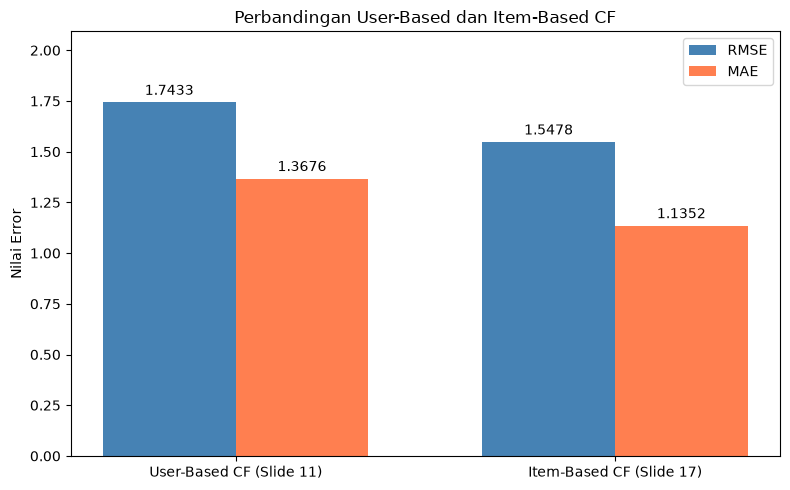

In [13]:
algoritma = ringkasan_evaluasi["Algoritma"]
nilai_rmse = ringkasan_evaluasi["RMSE"]
nilai_mae = ringkasan_evaluasi["MAE"]

x = np.arange(len(algoritma))
lebar = 0.35

plt.figure(figsize=(8, 5))
batang_rmse = plt.bar(x - lebar / 2, nilai_rmse, width=lebar, label="RMSE", color="steelblue")
batang_mae = plt.bar(x + lebar / 2, nilai_mae, width=lebar, label="MAE", color="coral")

plt.bar_label(batang_rmse, fmt="%.4f", padding=3)
plt.bar_label(batang_mae, fmt="%.4f", padding=3)

plt.title("Perbandingan User-Based dan Item-Based CF")
plt.xticks(x, algoritma)
plt.ylabel("Nilai Error")
plt.ylim(0, max(nilai_rmse.max(), nilai_mae.max()) + 0.35)
plt.legend()
plt.tight_layout()
plt.show()

6. Export Model ke Folder models

In [14]:
os.makedirs("models", exist_ok=True)

judul_terpakai = set(tabel_pivot.index) | set(buku_populer["Book-Title"])
info_buku = buku_unik[buku_unik["Book-Title"].isin(judul_terpakai)][
    ["Book-Title", "Book-Author", "Year-Of-Publication", "Publisher", "Image-URL-L"]
].copy()

buku_populer.to_pickle("models/buku_populer.pkl")
info_buku.to_pickle("models/info_buku.pkl")
tabel_pivot.astype("float32").to_pickle("models/tabel_pivot.pkl")
df_kemiripan_item.astype("float32").to_pickle("models/kemiripan_item.pkl")
df_kemiripan_user.astype("float32").to_pickle("models/kemiripan_user.pkl")
ringkasan_evaluasi.to_pickle("models/ringkasan_evaluasi.pkl")

print("berhasil menyimpan ke folder models")
daftar_file = [
    "buku_populer.pkl",
    "info_buku.pkl",
    "tabel_pivot.pkl",
    "kemiripan_item.pkl",
    "kemiripan_user.pkl",
    "ringkasan_evaluasi.pkl",
]
for nama_file in daftar_file:
    jalur = os.path.join("models", nama_file)
    ukuran_mb = os.path.getsize(jalur) / (1024 * 1024)
    print(f"- {nama_file:<24} : {ukuran_mb:.2f} MB")

berhasil menyimpan ke folder models
- buku_populer.pkl         : 0.01 MB
- info_buku.pkl            : 0.17 MB
- tabel_pivot.pkl          : 6.42 MB
- kemiripan_item.pkl       : 4.59 MB
- kemiripan_user.pkl       : 8.94 MB
- ringkasan_evaluasi.pkl   : 0.00 MB
